# **1. Import Library**

In [ ]:
!pip install google-play-scraper

import pandas as pd  # Pandas untuk manipulasi dan analisis data
pd.options.mode.chained_assignment = None  # Menonaktifkan peringatan chaining
import numpy as np  # NumPy untuk komputasi numerik
seed = 0
np.random.seed(seed)  # Mengatur seed untuk reproduktibilitas
import matplotlib.pyplot as plt  # Matplotlib untuk visualisasi data
import seaborn as sns  # Seaborn untuk visualisasi data statistik, mengatur gaya visualisasi
from sklearn.metrics import accuracy_score

import datetime as dt  # Manipulasi data waktu dan tanggal
import re  # Modul untuk bekerja dengan ekspresi reguler
import string  # Berisi konstanta string, seperti tanda baca
from nltk.tokenize import word_tokenize  # Tokenisasi teks
from nltk.corpus import stopwords  # Daftar kata-kata berhenti dalam teks

!pip install sastrawi
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory  # Stemming (penghilangan imbuhan kata) dalam bahasa Indonesia
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory  # Menghapus kata-kata berhenti dalam bahasa Indonesia

from wordcloud import WordCloud  # Membuat visualisasi berbentuk awan kata (word cloud) dari teks

import nltk  # Import pustaka NLTK (Natural Language Toolkit).
nltk.download('punkt')  # Mengunduh dataset yang diperlukan untuk tokenisasi teks.
nltk.download('punkt_tab')
nltk.download('stopwords')  # Mengunduh dataset yang berisi daftar kata-kata berhenti (stopwords) dalam berbagai bahasa.
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
import nltk
import csv
import requests
from io import StringIO

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from wordcloud import WordCloud
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import to_categorical

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
import gdown
from google.colab import files

url = f"https://drive.google.com/uc?id=1Xixg1wm84AeZ8m9o9HWYPRpqQJuyyU_P"
gdown.download(url, "wond.csv", quiet=False)


Downloading...
From: https://drive.google.com/uc?id=1Xixg1wm84AeZ8m9o9HWYPRpqQJuyyU_P
To: /content/wond.csv
100%|██████████| 6.09M/6.09M [00:00<00:00, 67.1MB/s]


'wond.csv'

In [ ]:
app_reviews_df = pd.read_csv("wond.csv")

# Menghitung jumlah baris dan kolom dalam DataFrame
jumlah_ulasan, jumlah_kolom = app_reviews_df.shape

In [ ]:
# Menampilkan lima baris pertama dari DataFrame app_reviews_df
app_reviews_df.head()

,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion
0,66bb091b-b621-41a6-b5be-2d6360e299a5,Fitra Ulfha,https://play-lh.googleusercontent.com/a/ACg8oc...,sangat baik,5,0,1.6.1,2026-10-19 03:32:59,"Hai Kak Fitra Ulfhab, terima kasih atas keperc...",2026-10-19 07:44:13,1.6.1
1,20ea0a1f-b836-4d66-ae26-14c66464adab,Putu Pande,https://play-lh.googleusercontent.com/a-/ALV-U...,bagus sekali makasi BNI,5,0,1.6.1,2026-10-19 03:31:55,"Hai Kak Putu Pande, terima kasih atas kepercay...",2026-10-19 07:43:12,1.6.1
2,d9183104-43ab-4ba8-b0e1-828a23bae668,Candle Dev,https://play-lh.googleusercontent.com/a/ACg8oc...,gagal mentransfer namun uang tidak bisa kembal...,1,0,NaN,2026-10-19 03:29:05,"Hai Kak Candle Dev, maaf buat kendalanya ya Ka...",2026-10-19 12:07:34,NaN
3,15f96386-3c50-47e8-abba-9b25a43f4603,Holden Panjaitan,https://play-lh.googleusercontent.com/a-/ALV-U...,wondr makin jaya di udara,5,0,1.5.0,2026-10-19 03:28:41,"Hai Kak Holden Panjaitan, terima kasih atas ke...",2026-10-19 07:42:23,1.5.0
4,4ee3cb83-7e57-4c69-a71c-89b4579a0265,Eka Juliyanzah,https://play-lh.googleusercontent.com/a-/ALV-U...,mau pengaktifan rekening malah ga jelas sistem...,1,0,1.6.1,2026-10-19 03:21:49,"Halo Kak Eka Juliyanzah, maaf bikin tidak nyam...",2026-10-19 12:06:59,1.6.1


In [ ]:
# Menampilkan informasi tentang DataFrame app_reviews_df
app_reviews_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   reviewId              16000 non-null  object
 1   userName              16000 non-null  object
 2   userImage             16000 non-null  object
 3   content               16000 non-null  object
 4   score                 16000 non-null  int64 
 5   thumbsUpCount         16000 non-null  int64 
 6   reviewCreatedVersion  14150 non-null  object
 7   at                    16000 non-null  object
 8   replyContent          8285 non-null   object
 9   repliedAt             8285 non-null   object
 10  appVersion            14150 non-null  object
dtypes: int64(2), object(9)
memory usage: 1.3+ MB


# **3. Preprocessing & Cleaning Data**

In [ ]:
# Menghapus fitur yang tidak diperlukan sesuai dengan kolom yang ada pada data
kolom_yang_akan_dihapus = [
    'reviewId',
    'userName',
    'userImage',
    'replyContent',
    'repliedAt',
    'reviewCreatedVersion',
    'appVersion'
]

# Memastikan hanya menghapus kolom yang benar-benar ada di DataFrame
kolom_ada = [col for col in kolom_yang_akan_dihapus if col in app_reviews_df.columns]
app_reviews_df = app_reviews_df.drop(columns=kolom_ada)

app_reviews_df.head()

,content,score,thumbsUpCount,at
0,sangat baik,5,0,2026-10-19 03:32:59
1,bagus sekali makasi BNI,5,0,2026-10-19 03:31:55
2,gagal mentransfer namun uang tidak bisa kembal...,1,0,2026-10-19 03:29:05
3,wondr makin jaya di udara,5,0,2026-10-19 03:28:41
4,mau pengaktifan rekening malah ga jelas sistem...,1,0,2026-10-19 03:21:49


In [ ]:
# Mengecek dataset menggunakan isnull().sum()
app_reviews_df.isnull().sum()

,0
content,0
score,0
thumbsUpCount,0
at,0


In [ ]:
# Membuat DataFrame baru (clean_df) dengan menghapus baris yang memiliki nilai yang hilang (NaN) dari app_reviews_df
app_reviews_df = app_reviews_df.dropna()

# Mengecek dataset menggunakan isnull().sum()
app_reviews_df.isnull().sum()

,0
content,0
score,0
thumbsUpCount,0
at,0


In [ ]:
# Menghapus baris duplikat dari DataFrame clean_df
app_reviews_df  = app_reviews_df.drop_duplicates()

# Menghitung jumlah baris dan kolom dalam DataFrame clean_df setelah menghapus duplikat
jumlah_ulasan_setelah_hapus_duplikat, jumlah_kolom_setelah_hapus_duplikat = app_reviews_df.shape

In [ ]:
# Mengecek dataset menggunakan duplicated().sum()
app_reviews_df.duplicated().sum()

np.int64(0)

 **CLEANING**

In [ ]:
def cleaningText(text):
    # Proteksi jika tipe data bukan string
    text = str(text)
    text = re.sub(r'@[A-Za-z0-9]+', '', text)  # hapus mention
    text = re.sub(r'#[A-Za-z0-9]+', '', text)  # hapus hashtag
    text = re.sub(r'RT[\s]+', '', text)        # hapus RT
    text = re.sub(r"http\S+", '', text)        # hapus link
    text = re.sub(r'[0-9]+', '', text)         # hapus angka
    text = re.sub(r'[^\w\s]', '', text)        # hapus simbol
    text = text.replace('\n', ' ')             # hapus newline
    text = text.translate(str.maketrans('', '', string.punctuation))  # hapus tanda baca
    text = text.strip()                        # hapus spasi di awal/akhir
    return text

def casefoldingText(text):
    return str(text).lower()

def tokenizingText(text):
    # Jika input berupa list, kembalikan langsung
    if isinstance(text, list):
        return text
    return word_tokenize(str(text))

def filteringText(text):
    listStopwords = set(stopwords.words('indonesian'))
    listStopwords1 = set(stopwords.words('english'))
    listStopwords.update(listStopwords1)
    # Tambahan stopword khas review agar hasil sentimen lebih bersih
    listStopwords.update(['iya','yaa','gak','nya','na','sih','ku','di','ga','ya','gaa','loh','kah','woi','woii','woy'])
    filtered = [txt for txt in text if txt not in listStopwords]
    return filtered

def stemmingText(text):
    factory = StemmerFactory()
    stemmer = factory.create_stemmer()
    # jika input berupa list, ubah ke string
    if isinstance(text, list):
        text = ' '.join(text)
    words = str(text).split()
    stemmed_words = [stemmer.stem(word) for word in words]
    return ' '.join(stemmed_words)

def toSentence(list_words):
    if isinstance(list_words, list):
        return ' '.join(str(word) for word in list_words)
    return str(list_words)

In [ ]:
slangwords = {
    "gak": "tidak",
    "ga": "tidak",
    "gk": "tidak",
    "nggak": "tidak",
    "ngga": "tidak",
    "yg": "yang",
    "udah": "sudah",
    "udh": "sudah",
    "aja": "saja",
    "bgt": "banget",
    "pake": "pakai",
    "gmna": "gimana",
    "knp": "kenapa",
    "kalo": "kalau",
    "blm": "belum",
    "tp": "tapi",
    "utk": "untuk",
    "dgn": "dengan",
    "krn": "karena",
    "dr": "dari",
    "doang": "saja",
    "cuman": "cuma",
    "gaada": "tidak ada",
    "gada": "tidak ada",
    "apk": "aplikasi",
    "tf": "transfer",
    "eror": "error",
    "makasi": "terima kasih",
    "makasih": "terima kasih",
    "skrg": "sekarang"
}

def fix_slangwords(text):
    words = text.split()
    fixed_words = []
    for word in words:
        word_lower = word.lower()
        if word_lower in slangwords:
            fixed_words.append(slangwords[word_lower])
        else:
            fixed_words.append(word)
    return ' '.join(fixed_words)

In [ ]:
# Membersihkan teks dan menyimpannya di kolom 'text_clean'
app_reviews_df['text_clean'] = app_reviews_df['content'].apply(cleaningText)

# Mengubah huruf dalam teks menjadi huruf kecil dan menyimpannya di 'text_casefoldingText'
app_reviews_df['text_casefoldingText'] = app_reviews_df['text_clean'].apply(casefoldingText)

# Mengganti kata-kata slang dengan kata-kata standar dan menyimpannya di 'text_slangwords'
app_reviews_df['text_slangwords'] = app_reviews_df['text_casefoldingText'].apply(fix_slangwords)

# Memecah teks menjadi token (kata-kata) dan menyimpannya di 'text_tokenizingText'
app_reviews_df['text_tokenizingText'] = app_reviews_df['text_slangwords'].apply(tokenizingText)

# Menghapus kata-kata stop (kata-kata umum) dan menyimpannya di 'text_stopword'
app_reviews_df['text_stopword'] = app_reviews_df['text_tokenizingText'].apply(filteringText)

**PELEBELAN DATA**

In [ ]:
# === 1. Unduh dan baca kamus positif (Menggunakan InSet Lexicon yang populer) ===
lexicon_positive = dict()

# URL alternatif InSet positif yang sering digunakan
url_pos = 'https://raw.githubusercontent.com/fajri91/InSet/master/positive.tsv'
response = requests.get(url_pos)
if response.status_code == 200:
    # InSet menggunakan pemisah tab (\t) dengan format: kata[tab]skor
    reader = csv.reader(StringIO(response.text), delimiter='\t')
    for row in reader:
        if len(row) == 2:
            try:
                lexicon_positive[row[0].strip()] = int(row[1])
            except ValueError:
                continue
else:
    print("⚠️ Gagal mengambil lexicon positif")

# === 2. Unduh dan baca kamus negatif (Menggunakan InSet Lexicon yang populer) ===
lexicon_negative = dict()

url_neg = 'https://raw.githubusercontent.com/fajri91/InSet/master/negative.tsv'
response = requests.get(url_neg)
if response.status_code == 200:
    reader = csv.reader(StringIO(response.text), delimiter='\t')
    for row in reader:
        if len(row) == 2:
            try:
                lexicon_negative[row[0].strip()] = int(row[1])
            except ValueError:
                continue
else:
    print("⚠️ Gagal mengambil lexicon negatif")

In [ ]:
# Fungsi untuk menentukan polaritas sentimen dari tweet

def sentiment_analysis_lexicon_indonesia(text, threshold=0.05):
    score = 0
    for word in text:
        if word in lexicon_positive:
            score += lexicon_positive[word]
        elif word in lexicon_negative:
            score += lexicon_negative[word]

    if score > threshold:
        polarity = 'positive'
    elif score < -threshold:
        polarity = 'negative'
    else:
        polarity = 'neutral'
    return score, polarity
    # Mengembalikan skor sentimen dan polaritas teks

In [ ]:
results = app_reviews_df['text_stopword'].apply(sentiment_analysis_lexicon_indonesia)
results = list(zip(*results))
app_reviews_df['polarity_score'] = results[0]
app_reviews_df['polarity'] = results[1]
print(app_reviews_df['polarity'].value_counts())


polarity
positive    10208
neutral      3125
negative     2667
Name: count, dtype: int64


In [ ]:
app_reviews_df.head()

,content,score,thumbsUpCount,at,text_clean,text_casefoldingText,text_slangwords,text_tokenizingText,text_stopword,polarity_score,polarity
0,sangat baik,5,0,2026-10-19 03:32:59,sangat baik,sangat baik,sangat baik,"[sangat, baik]",[],0,neutral
1,bagus sekali makasi BNI,5,0,2026-10-19 03:31:55,bagus sekali makasi BNI,bagus sekali makasi bni,bagus sekali terima kasih bni,"[bagus, sekali, terima, kasih, bni]","[bagus, terima, kasih, bni]",6,positive
2,gagal mentransfer namun uang tidak bisa kembal...,1,0,2026-10-19 03:29:05,gagal mentransfer namun uang tidak bisa kembal...,gagal mentransfer namun uang tidak bisa kembal...,gagal mentransfer namun uang tidak bisa kembal...,"[gagal, mentransfer, namun, uang, tidak, bisa,...","[gagal, mentransfer, uang, sedih, banget]",-8,negative
3,wondr makin jaya di udara,5,0,2026-10-19 03:28:41,wondr makin jaya di udara,wondr makin jaya di udara,wondr makin jaya di udara,"[wondr, makin, jaya, di, udara]","[wondr, jaya, udara]",0,neutral
4,mau pengaktifan rekening malah ga jelas sistem...,1,0,2026-10-19 03:21:49,mau pengaktifan rekening malah ga jelas sistem...,mau pengaktifan rekening malah ga jelas sistem...,mau pengaktifan rekening malah tidak jelas sis...,"[mau, pengaktifan, rekening, malah, tidak, jel...","[pengaktifan, rekening, sistemnya, persulit, c...",3,positive


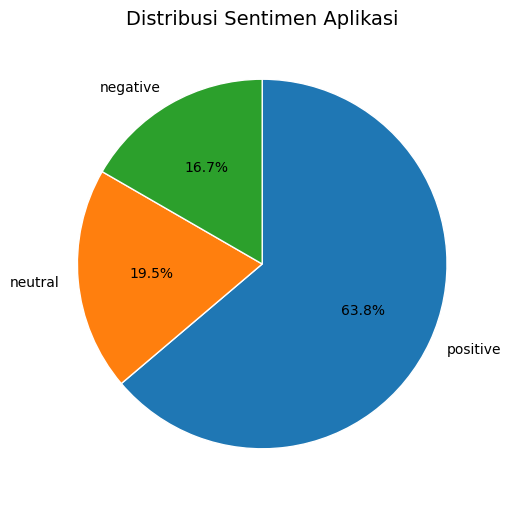

In [ ]:
# Hitung jumlah masing-masing kategori polaritas
polarity_counts = app_reviews_df['polarity'].value_counts()

# Buat pie chart
plt.figure(figsize=(6,6))
plt.pie(
    polarity_counts,
    labels=polarity_counts.index,
    autopct='%1.1f%%',       # tampilkan persentase
    startangle=90,           # mulai dari atas biar lebih rapi
    counterclock=False,      # arah searah jarum jam
    wedgeprops={'edgecolor': 'white'}  # kasih garis putih antar potongan
)

plt.title('Distribusi Sentimen Aplikasi', fontsize=14)
plt.show()

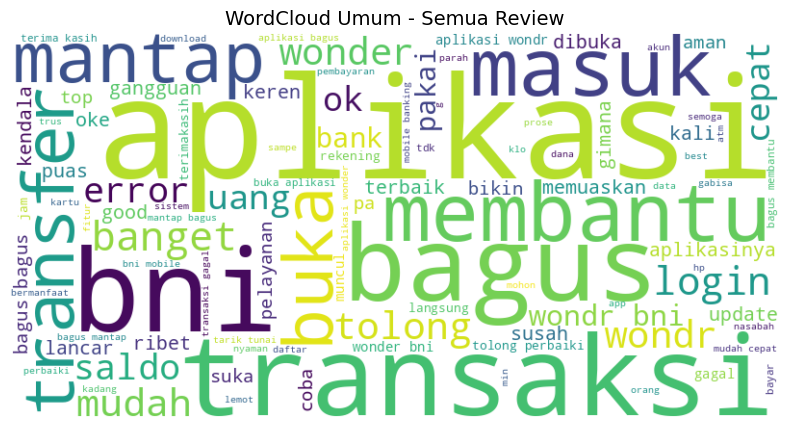

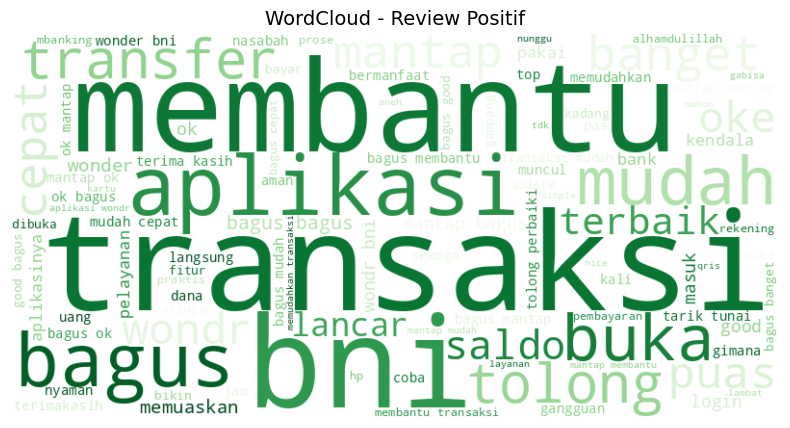

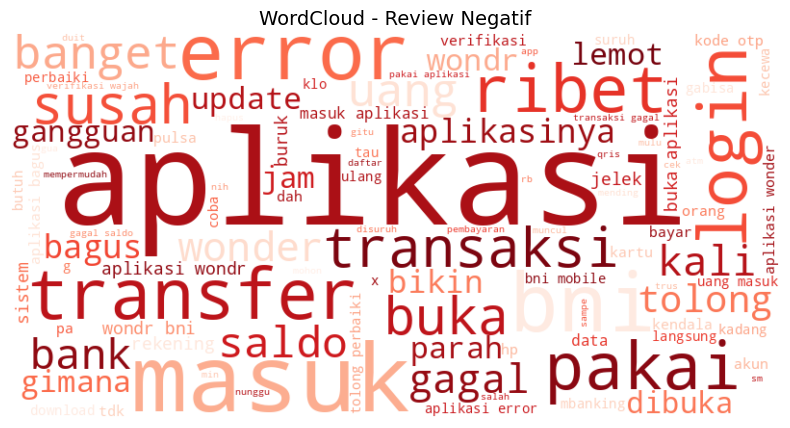

In [ ]:

app_reviews_df['text_stopword'] = app_reviews_df['text_stopword'].apply(
    lambda x: ' '.join(x) if isinstance(x, list) else str(x)
)

text_all = ' '.join(app_reviews_df['text_stopword'])
wordcloud_all = WordCloud(
    width=800,
    height=400,
    background_color='white',
    max_words=100
).generate(text_all)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_all, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud Umum - Semua Review', fontsize=14)
plt.show()

text_positive = ' '.join(
    app_reviews_df[app_reviews_df['polarity'] == 'positive']['text_stopword']
)
wordcloud_positive = WordCloud(
    width=800,
    height=400,
    background_color='white',
    colormap='Greens',
    max_words=100
).generate(text_positive)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_positive, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud - Review Positif', fontsize=14)
plt.show()

text_negative = ' '.join(
    app_reviews_df[app_reviews_df['polarity'] == 'negative']['text_stopword']
)
wordcloud_negative = WordCloud(
    width=800,
    height=400,
    background_color='white',
    colormap='Reds',
    max_words=100
).generate(text_negative)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_negative, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud - Review Negatif', fontsize=14)
plt.show()

In [ ]:
app_reviews_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   content               16000 non-null  object
 1   score                 16000 non-null  int64 
 2   thumbsUpCount         16000 non-null  int64 
 3   at                    16000 non-null  object
 4   text_clean            16000 non-null  object
 5   text_casefoldingText  16000 non-null  object
 6   text_slangwords       16000 non-null  object
 7   text_tokenizingText   16000 non-null  object
 8   text_stopword         16000 non-null  object
 9   polarity_score        16000 non-null  int64 
 10  polarity              16000 non-null  object
dtypes: int64(3), object(8)
memory usage: 1.3+ MB


In [ ]:
app_reviews_df['polarity'].value_counts(normalize=True)


,proportion
polarity,
positive,0.638000
neutral,0.195312
negative,0.166687


In [ ]:
app_reviews_df.to_csv('data_cleaned_final.csv', index=False)